# Classificação de imagens com redes convolucionais

Neste estudo, vou explorar o CIFAR-10 e comparar duas redes
convolucionais para classificação de imagens.

Primeiro, vou observar as imagens e a distribuição das classes.
Depois, vou preparar os dados, treinar os modelos e analisar seus erros.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)

Python: c:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\visao_computacional\.venv\Scripts\python.exe
TensorFlow: 2.21.0


## Conhecendo os dados

O CIFAR-10 contém imagens coloridas de 32 × 32 pixels, distribuídas
em dez classes. Vou manter o conjunto de teste separado durante
a preparação e o treinamento.

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

# Cada imagem possui apenas uma classe.
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

CLASS_NAMES = [
    "avião",
    "automóvel",
    "pássaro",
    "gato",
    "cervo",
    "cachorro",
    "sapo",
    "cavalo",
    "navio",
    "caminhão",
]

print("Imagens para treino e validação:", X_train_full.shape)
print("Imagens para teste:", X_test.shape)
print("Tipo dos pixels:", X_train_full.dtype)
print("Intervalo dos pixels:", X_train_full.min(), "a", X_train_full.max())

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3752s 22us/step
Imagens para treino e validação: (50000, 32, 32, 3)
Imagens para teste: (10000, 32, 32, 3)
Tipo dos pixels: uint8
Intervalo dos pixels: 0 a 255


## Explorando as imagens

Cada imagem possui 32 × 32 pixels e três canais de cor: vermelho,
verde e azul. Vou visualizar alguns exemplos e verificar quantas
imagens existem em cada classe do conjunto de treino e validação.

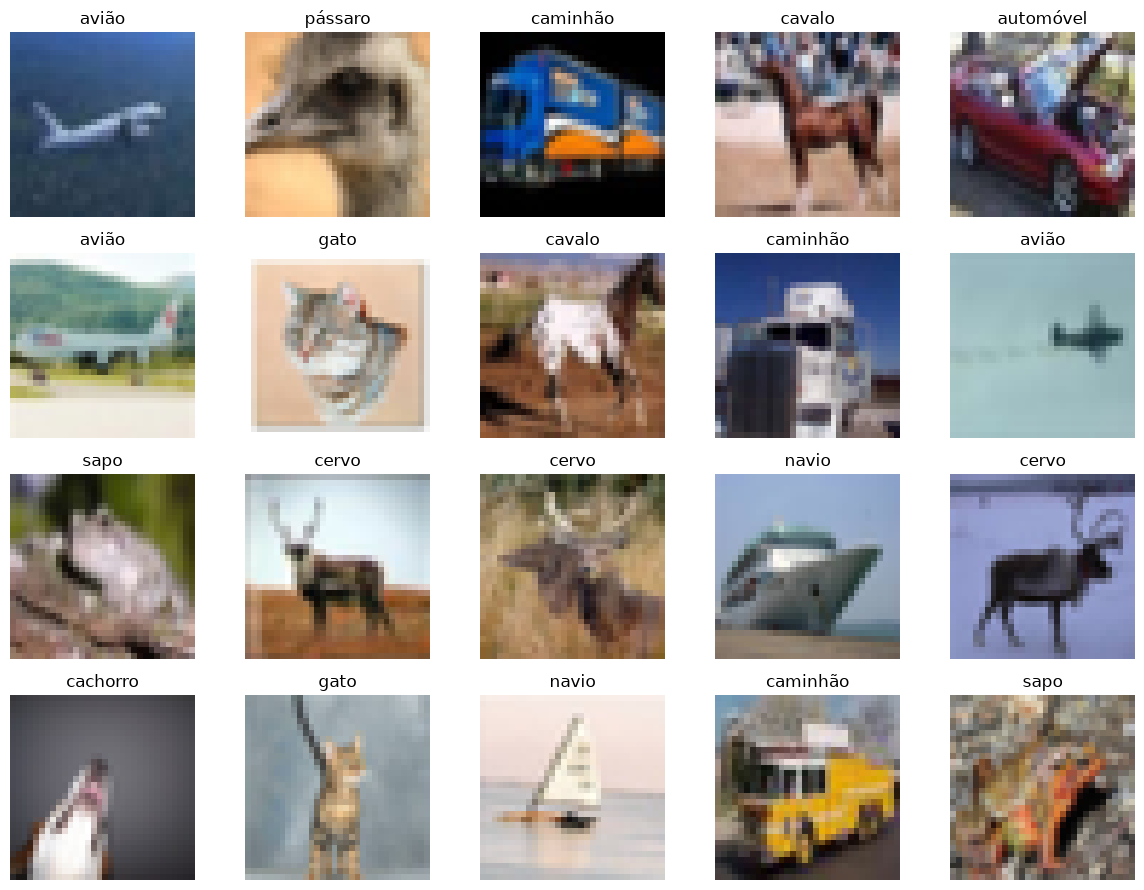

In [3]:
rng = np.random.default_rng(SEED)
indices = rng.choice(len(X_train_full), size=20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(12, 9))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(X_train_full[idx])
    ax.set_title(CLASS_NAMES[y_train_full[idx]])
    ax.axis("off")

plt.tight_layout()
plt.show()

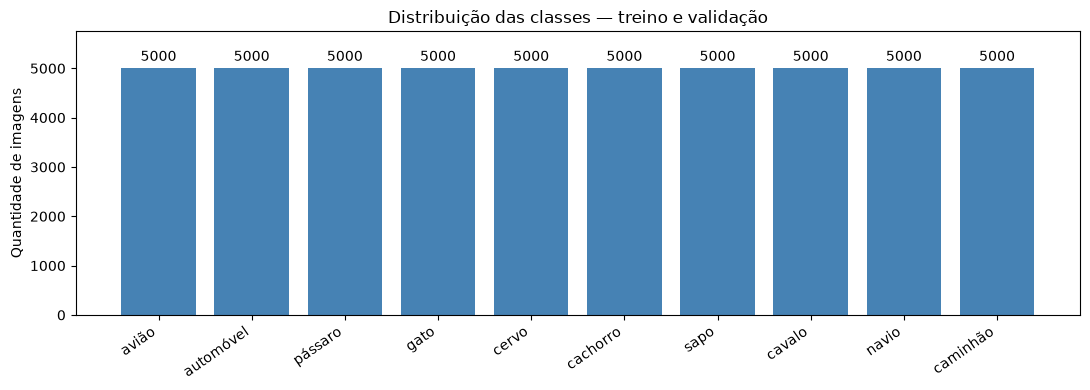

In [4]:
contagens = np.bincount(y_train_full, minlength=len(CLASS_NAMES))

fig, ax = plt.subplots(figsize=(11, 4))
barras = ax.bar(CLASS_NAMES, contagens, color="steelblue")
ax.bar_label(barras, padding=3)

ax.set_title("Distribuição das classes — treino e validação")
ax.set_ylabel("Quantidade de imagens")
ax.set_ylim(0, contagens.max() * 1.15)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Preparação dos dados

Vou reservar 10% das 50.000 imagens para validação, mantendo
a proporção das classes. Assim, serão 45.000 imagens para treino
e 5.000 para validação.

Os pixels serão convertidos para float32 e divididos por 255,
passando do intervalo [0, 255] para [0, 1].
O conjunto de teste continuará separado.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.10,
    stratify=y_train_full,
    random_state=SEED,
)

X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0

print("Treino:", X_train.shape, "| Rótulos:", y_train.shape)
print("Validação:", X_val.shape, "| Rótulos:", y_val.shape)
print("Tipo dos pixels:", X_train.dtype)
print("Intervalo no treino:", X_train.min(), "a", X_train.max())

Treino: (45000, 32, 32, 3) | Rótulos: (45000,)
Validação: (5000, 32, 32, 3) | Rótulos: (5000,)
Tipo dos pixels: float32
Intervalo no treino: 0.0 a 1.0


## CNN inicial

A rede terá três blocos de convolução e redução espacial.
As convoluções aprenderão padrões das imagens, enquanto o
MaxPooling reduzirá o tamanho das representações.

Ao final, uma camada densa combinará os padrões aprendidos.
A saída terá dez valores, um para cada classe.

In [6]:
from tensorflow.keras import Sequential, layers

tf.keras.utils.set_random_seed(SEED)

model_baseline = Sequential(
    [
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(16, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(32, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(64, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ],
    name="cnn_baseline",
)

model_baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,682 (158.91 KB)

 Trainable params: 40,682 (158.91 KB)

 Non-trainable params: 0 (0.00 B)

## Treinamento da CNN inicial

Vou treinar a rede por dez épocas, com lotes de 64 imagens.
A cada época, vou acompanhar a perda e a acurácia no treino
e na validação.

A validação ajuda a observar como a rede se comporta em imagens
que não foram usadas para atualizar seus pesos.

In [7]:
history_baseline = model_baseline.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    shuffle=True,
    verbose=1,
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.3966 - loss: 1.6495 - val_accuracy: 0.4900 - val_loss: 1.4111
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5157 - loss: 1.3492 - val_accuracy: 0.5436 - val_loss: 1.2839
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5658 - loss: 1.2203 - val_accuracy: 0.5804 - val_loss: 1.1803
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6031 - loss: 1.1278 - val_accuracy: 0.6036 - val_loss: 1.1298
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6286 - loss: 1.0578 - val_accuracy: 0.6124 - val_loss: 1.1030
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6485 - loss: 1.0035 - val_accuracy: 0.6246 - val_loss: 1.0787
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6662 - loss: 0.9582 - val_accuracy: 0.6332 - val_loss: 1.0656
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6811 - loss: 0.9192 - val_accuracy: 0.

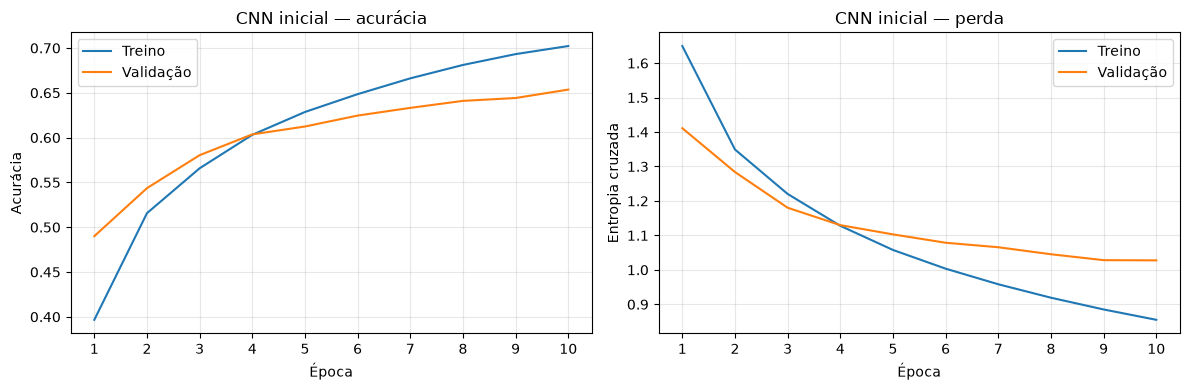

In [8]:
epocas = range(1, len(history_baseline.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epocas, history_baseline.history["accuracy"], label="Treino"
)
axes[0].plot(
    epocas, history_baseline.history["val_accuracy"], label="Validação"
)
axes[0].set_title("CNN inicial — acurácia")
axes[0].set_ylabel("Acurácia")

axes[1].plot(
    epocas, history_baseline.history["loss"], label="Treino"
)
axes[1].plot(
    epocas, history_baseline.history["val_loss"], label="Validação"
)
axes[1].set_title("CNN inicial — perda")
axes[1].set_ylabel("Entropia cruzada")

for ax in axes:
    ax.set_xlabel("Época")
    ax.set_xticks(list(epocas))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observações sobre o treinamento

A acurácia de validação passou de 49,00% para 65,36%, enquanto
a perda de validação diminuiu ao longo das dez épocas.

A acurácia final de treino foi de 70,02%, cerca de 4,66 pontos
percentuais acima da validação. Há uma diferença entre os conjuntos,
mas não ocorreu uma piora sustentada da perda de validação neste
treinamento.

## Segunda CNN

Vou testar uma rede com dois convolucionais por bloco e mais filtros.
Também vou incluir:

- Aumento de dados: espelhamento horizontal e pequenas translações,
  aplicados durante o treinamento.
- Batch Normalization: normalização das ativações intermediárias.
- Dropout: desativação aleatória de parte das unidades durante o treino.

Vou manter a mesma divisão de treino e validação para comparar
as duas configurações. Como várias mudanças serão aplicadas juntas,
a comparação não permitirá atribuir o resultado a uma técnica isolada.

In [9]:
tf.keras.utils.set_random_seed(SEED)

model_improved = Sequential(
    [
        layers.Input(shape=(32, 32, 3)),

        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomTranslation(0.1, 0.1, seed=SEED + 1),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.2),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.3),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.4),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax"),
    ],
    name="cnn_melhorada",
)

model_improved.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model_improved.summary()

Model: "cnn_melhorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

## Treinamento da segunda CNN

O treinamento terá até 30 épocas. Vou acompanhar a perda de validação
para salvar o melhor modelo e interromper o treino caso ela deixe
de melhorar por cinco épocas.

A taxa de aprendizado será reduzida quando a perda de validação
ficar duas épocas sem melhorar.

In [10]:
from pathlib import Path

# Localiza a raiz tanto ao executar da pasta notebooks quanto do projeto.
ROOT = Path.cwd().resolve()

if not (ROOT / "pyproject.toml").is_file():
    ROOT = next(
        pasta
        for pasta in ROOT.parents
        if (pasta / "pyproject.toml").is_file()
    )

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "classificador_cifar10.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
]

history_improved = model_improved.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    shuffle=True,
    callbacks=callbacks,
    verbose=1,
)

# Usa exatamente a versão salva para as próximas avaliações.
model_improved = tf.keras.models.load_model(MODEL_PATH)

melhor_epoca = int(np.argmin(history_improved.history["val_loss"])) + 1

print("Épocas executadas:", len(history_improved.history["loss"]))
print("Melhor época pela perda de validação:", melhor_epoca)
print("Modelo salvo em:", MODEL_PATH)

Epoch 1/30
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.4015 - loss: 1.7464
Epoch 1: val_loss improved from None to 1.26867, saving model to C:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\visao_computacional\models\classificador_cifar10.keras

Epoch 1: finished saving model to C:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\visao_computacional\models\classificador_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 67ms/step - accuracy: 0.4015 - loss: 1.7464 - val_accuracy: 0.5364 - val_loss: 1.2687 - learning_rate: 0.0010
Epoch 2/30
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.5653 - loss: 1.2238
Epoch 2: val_loss did not improve from 1.26867
704/704 ━━━━━━━━━━━━━━━━━━━━ 60s 85ms/step - accuracy: 0.5653 - loss: 1.2238 - val_accuracy: 0.5650 - val_loss: 1.2688 - learning_rate: 0.0010
Epoch 3/30
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.6374 - loss: 1.0304
Epoch 3: ReduceLROnPlateau reducing 

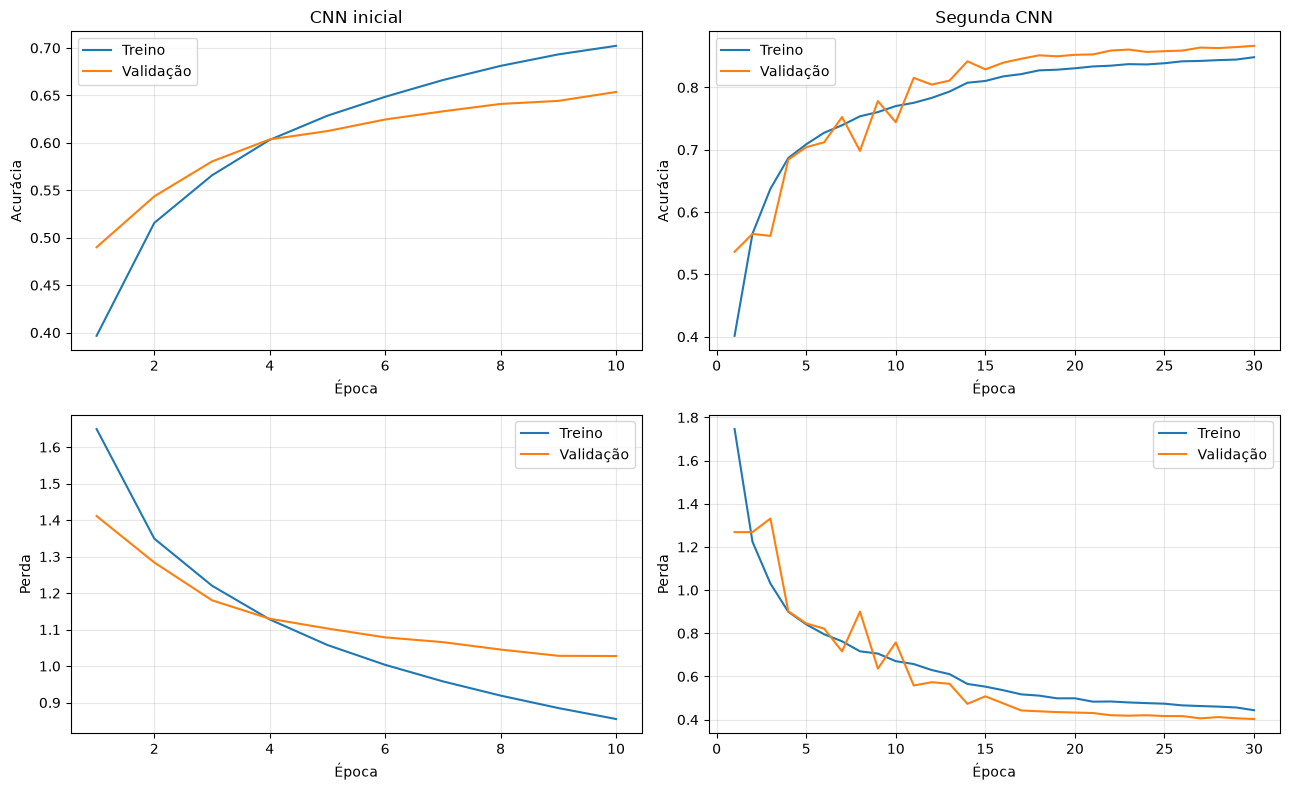

Segunda CNN — época com menor perda de validação:
Época: 30
Acurácia de validação: 86.68%
Perda de validação: 0.4029
Modelo salvo em: C:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\visao_computacional\models\classificador_cifar10.keras


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for col, (historico, nome) in enumerate([
    (history_baseline, "CNN inicial"),
    (history_improved, "Segunda CNN"),
]):
    dados = historico.history
    epocas = range(1, len(dados["loss"]) + 1)

    axes[0, col].plot(epocas, dados["accuracy"], label="Treino")
    axes[0, col].plot(epocas, dados["val_accuracy"], label="Validação")
    axes[0, col].set_title(nome)
    axes[0, col].set_ylabel("Acurácia")

    axes[1, col].plot(epocas, dados["loss"], label="Treino")
    axes[1, col].plot(epocas, dados["val_loss"], label="Validação")
    axes[1, col].set_ylabel("Perda")

for ax in axes.flat:
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

melhor_idx = int(np.argmin(history_improved.history["val_loss"]))

print("Segunda CNN — época com menor perda de validação:")
print("Época:", melhor_idx + 1)
print(
    "Acurácia de validação:",
    f"{history_improved.history['val_accuracy'][melhor_idx]:.2%}",
)
print(
    "Perda de validação:",
    f"{history_improved.history['val_loss'][melhor_idx]:.4f}",
)
print("Modelo salvo em:", MODEL_PATH)

### Comparação das curvas

A segunda CNN apresentou maior acurácia e menor perda de validação
que a CNN inicial. Houve oscilações nas primeiras épocas, seguidas
de uma melhora mais estável.

A acurácia de validação ficou acima da de treino em boa parte da
execução. Isso é compatível com o uso de Dropout e aumento de dados
durante o treinamento.

A comparação envolve mudanças na arquitetura, na regularização
e na quantidade de épocas; portanto, não permite identificar
a contribuição isolada de cada mudança.

In [12]:
# X_test ainda contém os pixels originais entre 0 e 255.
X_test_normalized = X_test.astype("float32") / 255.0

resultados_teste = {}

for nome, modelo in [
    ("CNN inicial", model_baseline),
    ("Segunda CNN", model_improved),
]:
    resultado = modelo.evaluate(
        X_test_normalized,
        y_test,
        batch_size=64,
        verbose=0,
        return_dict=True,
    )
    resultados_teste[nome] = resultado

    print(
        f"{nome}: acurácia = {resultado['accuracy']:.2%}"
        f" | perda = {resultado['loss']:.4f}"
    )

CNN inicial: acurácia = 64.46% | perda = 1.0529
Segunda CNN: acurácia = 85.67% | perda = 0.4335


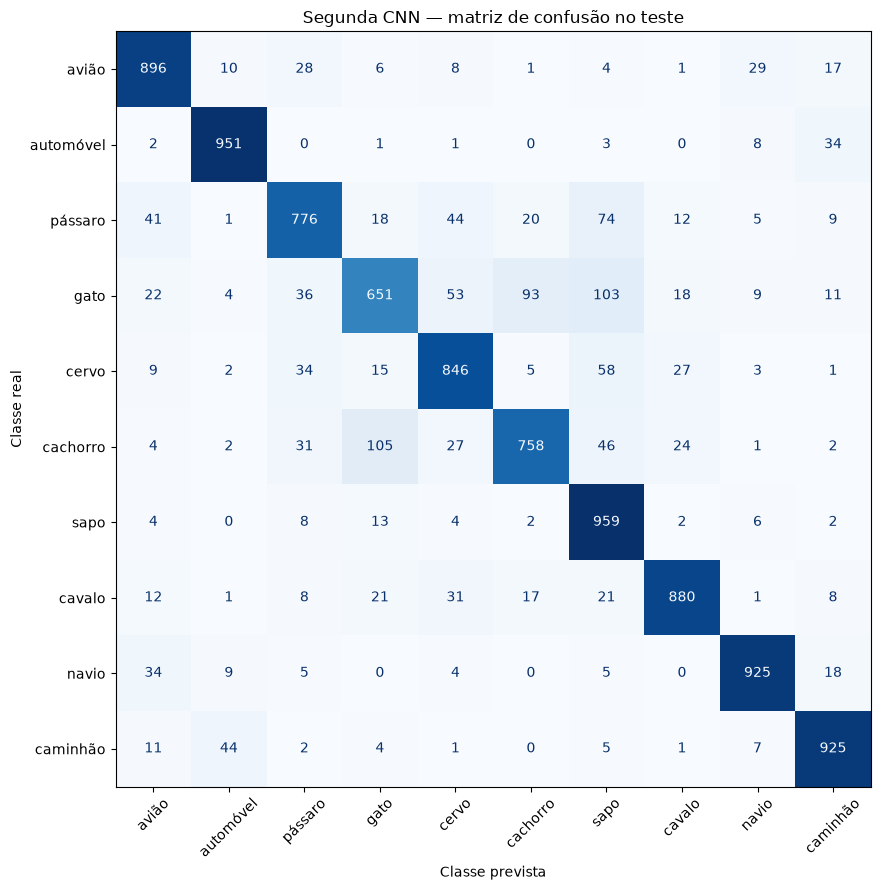

Recall por classe — proporção de imagens da classe reconhecidas:
     avião: 89.60%
 automóvel: 95.10%
   pássaro: 77.60%
      gato: 65.10%
     cervo: 84.60%
  cachorro: 75.80%
      sapo: 95.90%
    cavalo: 88.00%
     navio: 92.50%
  caminhão: 92.50%

Cinco confusões mais frequentes:
cachorro → gato: 105 imagens
gato → sapo: 103 imagens
gato → cachorro: 93 imagens
pássaro → sapo: 74 imagens
cervo → sapo: 58 imagens


In [13]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

test_probs = model_improved.predict(
    X_test_normalized, batch_size=64, verbose=0
)
test_pred = test_probs.argmax(axis=1)

confusion = confusion_matrix(
    y_test, test_pred, labels=range(len(CLASS_NAMES))
)

fig, ax = plt.subplots(figsize=(10, 9))

ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)

ax.set_title("Segunda CNN — matriz de confusão no teste")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()

FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(
    FIGURES_DIR / "confusion_matrix_cifar10.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

recall_por_classe = confusion.diagonal() / confusion.sum(axis=1)

print("Recall por classe — proporção de imagens da classe reconhecidas:")
for nome, recall in zip(CLASS_NAMES, recall_por_classe):
    print(f"{nome:>10}: {recall:.2%}")

erros = confusion.copy()
np.fill_diagonal(erros, 0)
indices = np.argsort(erros.ravel())[::-1][:5]

print("\nCinco confusões mais frequentes:")
for indice in indices:
    real, prevista = np.unravel_index(indice, erros.shape)
    print(
        f"{CLASS_NAMES[real]} → {CLASS_NAMES[prevista]}:"
        f" {erros[real, prevista]} imagens"
    )

### Análise dos erros por classe

O desempenho variou entre as classes. Sapo e automóvel apresentaram
os maiores recalls, com 95,9% e 95,1%, respectivamente. Gato teve
o menor recall, com 65,1%.

As maiores confusões foram cachorro classificado como gato,
gato como sapo e gato como cachorro. A matriz mostra quais erros
foram frequentes, mas não permite identificar sozinha suas causas.

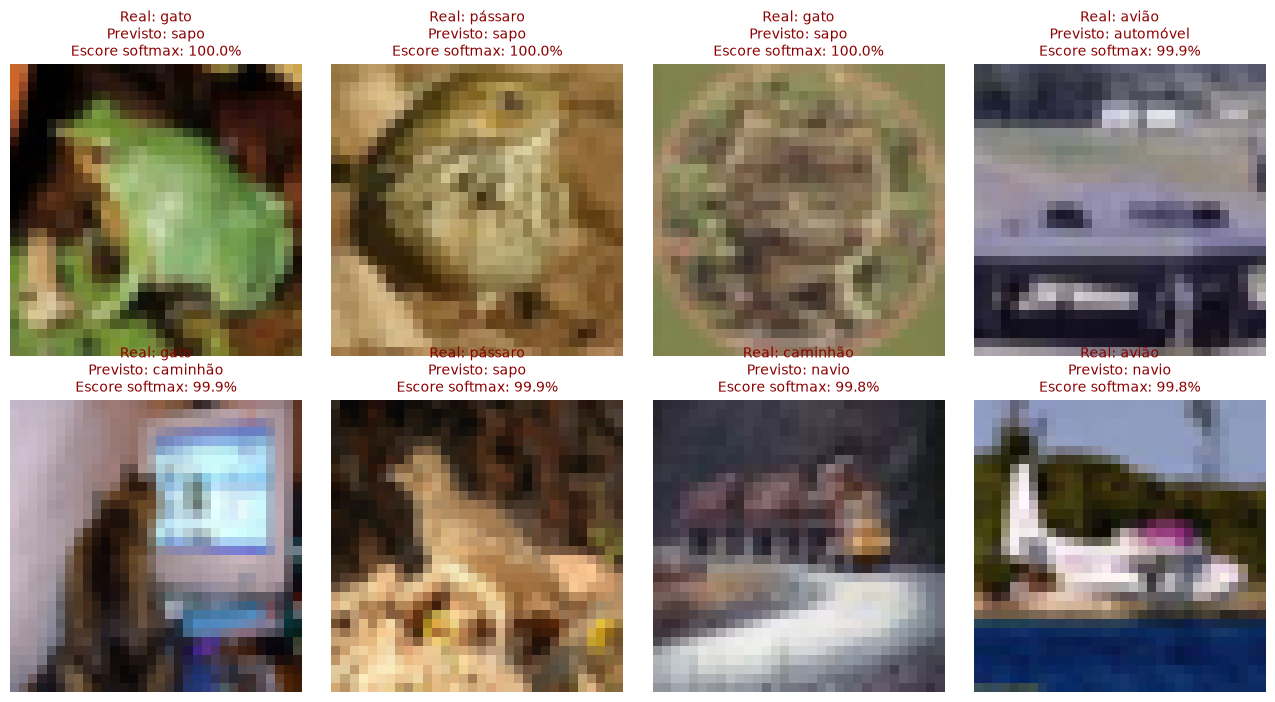

In [14]:
wrong = np.flatnonzero(test_pred != y_test)
scores = test_probs.max(axis=1)
selected = wrong[np.argsort(scores[wrong])[::-1][:8]]

fig, axes = plt.subplots(2, 4, figsize=(13, 7))

for ax, idx in zip(axes.flat, selected):
    ax.imshow(X_test[idx])
    ax.set_title(
        f"Real: {CLASS_NAMES[y_test[idx]]}\n"
        f"Previsto: {CLASS_NAMES[test_pred[idx]]}\n"
        f"Escore softmax: {scores[idx]:.1%}",
        color="darkred",
        fontsize=10,
    )
    ax.axis("off")

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "cifar10_erros_maior_escore.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [15]:
(_, _), (imagens_originais, rotulos_originais) = (
    tf.keras.datasets.cifar10.load_data()
)
rotulos_originais = rotulos_originais.ravel()

print(
    "Imagens na ordem original:",
    np.array_equal(X_test, imagens_originais),
)
print(
    "Rótulos na ordem original:",
    np.array_equal(y_test, rotulos_originais),
)
print(
    "Normalização corresponde às imagens:",
    np.allclose(
        X_test_normalized,
        imagens_originais.astype("float32") / 255.0,
    ),
)
print("Ordem das classes:", CLASS_NAMES)

Imagens na ordem original: True
Rótulos na ordem original: True
Normalização corresponde às imagens: True
Ordem das classes: ['avião', 'automóvel', 'pássaro', 'gato', 'cervo', 'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']


## Filtros e mapas de ativação

Vou visualizar alguns filtros da primeira camada convolucional
e suas respostas a uma imagem.

Os filtros são pesos aprendidos durante o treinamento. Os mapas
de ativação mostram como cada filtro responde às regiões da imagem.
Essa visualização não explica, sozinha, a decisão final da rede.

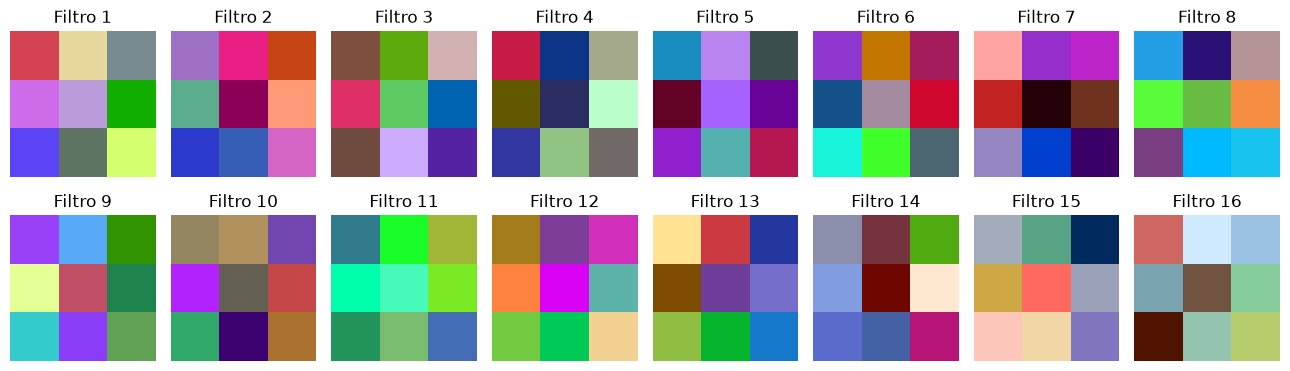

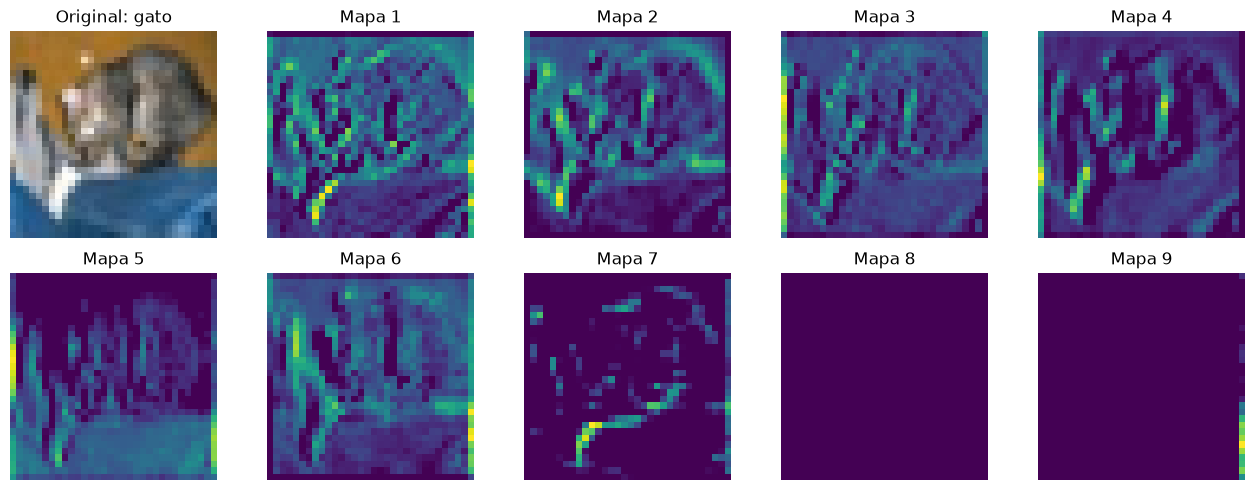

In [16]:
first_conv = next(
    layer
    for layer in model_improved.layers
    if isinstance(layer, layers.Conv2D)
)

# Visualização de 16 filtros RGB da primeira convolução.
pesos = first_conv.get_weights()[0]

fig, axes = plt.subplots(2, 8, figsize=(13, 4))

for i, ax in enumerate(axes.flat):
    filtro = pesos[:, :, :, i]
    filtro = (
        (filtro - filtro.min())
        / (filtro.max() - filtro.min() + 1e-8)
    )
    ax.imshow(filtro)
    ax.set_title(f"Filtro {i + 1}")
    ax.axis("off")

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "cifar10_filtros.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Resposta da primeira convolução a uma imagem normalizada.
idx = 0
mapas = first_conv(
    tf.convert_to_tensor(X_test_normalized[idx:idx + 1])
).numpy()[0]

fig, axes = plt.subplots(2, 5, figsize=(13, 5))

axes.flat[0].imshow(X_test[idx])
axes.flat[0].set_title(f"Original: {CLASS_NAMES[y_test[idx]]}")

for i, ax in enumerate(list(axes.flat)[1:]):
    ax.imshow(mapas[:, :, i], cmap="viridis")
    ax.set_title(f"Mapa {i + 1}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "cifar10_mapas_ativacao.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## Classificação a partir de um arquivo

A imagem será carregada em RGB, redimensionada para 32 × 32 pixels
e normalizada como no treinamento.

Para conferir o funcionamento, vou salvar uma imagem do teste
e carregá-la novamente pelo arquivo. Isso verifica o fluxo de leitura,
mas não representa uma avaliação com uma imagem externa.

O modelo sempre escolhe entre as dez classes aprendidas.

Classe real: sapo


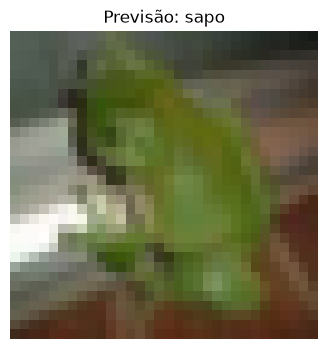

Três maiores escores softmax:
      sapo: 97.08%
   pássaro: 2.11%
     cervo: 0.38%


In [17]:
def classificar_imagem(caminho):
    imagem = tf.keras.utils.load_img(
        caminho,
        color_mode="rgb",
        target_size=(32, 32),
    )
    entrada = tf.keras.utils.img_to_array(imagem) / 255.0

    escores = model_improved.predict(
        entrada[np.newaxis, ...],
        verbose=0,
    )[0]
    top3 = np.argsort(escores)[::-1][:3]

    plt.figure(figsize=(4, 4))
    plt.imshow(imagem)
    plt.title(f"Previsão: {CLASS_NAMES[top3[0]]}")
    plt.axis("off")
    plt.show()

    print("Três maiores escores softmax:")
    for classe in top3:
        print(f"{CLASS_NAMES[classe]:>10}: {escores[classe]:.2%}")


INTERIM_DIR = ROOT / "data" / "interim"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

caminho_exemplo = INTERIM_DIR / "exemplo_teste.png"
tf.keras.utils.save_img(
    caminho_exemplo,
    X_test[7],
    scale=False,
)

print("Classe real:", CLASS_NAMES[y_test[7]])
classificar_imagem(caminho_exemplo)

In [18]:
import json
import pandas as pd

REPORTS_DIR = ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Histórico das duas redes.
historicos = {
    "cnn_inicial": history_baseline.history,
    "segunda_cnn": history_improved.history,
}
historicos = {
    nome: {
        metrica: [float(valor) for valor in valores]
        for metrica, valores in historico.items()
    }
    for nome, historico in historicos.items()
}

with (REPORTS_DIR / "cifar10_history.json").open(
    "w", encoding="utf-8"
) as arquivo:
    json.dump(historicos, arquivo, ensure_ascii=False, indent=2)

# Métricas do teste e configuração do experimento.
resumo = {
    "seed": SEED,
    "n_train": len(y_train),
    "n_validation": len(y_val),
    "n_test": len(y_test),
    "class_names": CLASS_NAMES,
    "selection_metric": "val_loss",
    "best_epoch": int(
        np.argmin(history_improved.history["val_loss"])
    ) + 1,
    "test_metrics": {
        nome: {
            metrica: float(valor)
            for metrica, valor in resultado.items()
        }
        for nome, resultado in resultados_teste.items()
    },
}

with (REPORTS_DIR / "cifar10_metrics.json").open(
    "w", encoding="utf-8"
) as arquivo:
    json.dump(resumo, arquivo, ensure_ascii=False, indent=2)

pd.DataFrame({
    "classe": CLASS_NAMES,
    "n_imagens": confusion.sum(axis=1),
    "n_acertos": confusion.diagonal(),
    "recall": recall_por_classe,
}).to_csv(
    REPORTS_DIR / "cifar10_per_class.csv",
    index=False,
    encoding="utf-8",
)

print("Relatórios salvos em:", REPORTS_DIR)
print("Modelo salvo em:", MODEL_PATH)

Relatórios salvos em: C:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\visao_computacional\reports
Modelo salvo em: C:\Users\Rafael Athaliba\Projetos Git\Machine_Learning\Machine_Learning_entrega\visao_computacional\models\classificador_cifar10.keras


## Conclusão

A CNN inicial alcançou 64,46% de acurácia no teste. A segunda CNN
alcançou 85,67%, uma diferença de 21,21 pontos percentuais.

A segunda configuração combinou maior capacidade, aumento de dados,
Batch Normalization, Dropout e mais épocas de treinamento. Como essas
mudanças foram aplicadas juntas, não é possível atribuir o ganho
a uma técnica isolada.

O desempenho variou entre as classes: sapo apresentou recall de 95,9%,
enquanto gato apresentou 65,1%. Também ocorreram erros com escores
softmax elevados, mostrando que um escore alto não garante acerto.

Os filtros e mapas de ativação permitiram observar respostas da
primeira convolução. O teste de leitura por arquivo utilizou uma
imagem do próprio conjunto de teste, sem representar uma avaliação
com fotografias externas.